# 6x6, J2 = 0: spin-basis vs eigenbasis ViT at matched shapes

**Question.** The 4x4 eigenbasis is a degenerate case (4 plaquette tokens on a
2x2 periodic grid), so the basis comparison belongs on 6x6. For every ViT shape
the eigenbasis has been run with on 6x6, how does the spin basis do with the
**same shape**, hence the same parameter count to within 0.1% (only the
embedding differs)?

| shape | layers | d_model | heads | params spin / eigen |
|---|---|---|---|---|
| L1 d90 | 1 | 90 | 15 | 99,495 / 99,585 |
| L2 d66 | 2 | 66 | 11 | 98,340 / 98,406 |
| L4 d48 | 4 | 48 | 8 | 99,792 / 99,840 |
| L8 d32 | 8 | 32 | 4 | 87,488 / 87,520 |
| L2 d72 | 2 | 72 | 12 | 116,784 / 116,856 |
| L8 d72 | 8 | 72 | 12 | 433,224 / 433,296 |

The spin runs are sweep `2026-10-09_00-49-27G8b47bde` (10,000 steps, AICR
b200-batch, **in progress**) plus the existing L2 d72 run from 2026-09-28. The
eigenbasis runs are the existing ones: the 2026-10-02 depth-vs-width sweep
(2,000 steps), its 2026-10-05 continuations, the 2026-09-21 L2 d72 runs and the
L8 d72 run continued to 26,000 steps.

**The runs differ in more than the basis.** The tables below list every setting
that differs within a matched pair, read from the run configs. The main ones:
- the eigenbasis runs use alpha = 1.25, the spin runs alpha = 2.0 (each basis's
  best-known value);
- most eigenbasis runs end at diag shift 1e-3, the spin runs at 1e-4;
- run lengths differ (2k to 26k steps).

So runs are compared **at equal step counts**, and settings differences are
shown next to every pair.

Reference: E0/site = -0.678872 (the value used in all earlier 6x6 analyses; the
literature QMC value is -0.678873, so relErr below ~1.5e-6 is not resolvable).

**Refresh** (the spin runs are still going; re-run all cells afterwards):

    rsync -av aicr:~/master/heisenberg_2d/data/ ~/Documents/master/heisenberg_2d/data/

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

def _find(name):
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / name).is_dir():
            return p / name
    raise FileNotFoundError(f"no '{name}' folder above {Path.cwd()}")

DATA = _find("data")

def run_dir(basis, sweep_prefix, run):
    # Sweep folders are matched by prefix: one spin folder carries a " 2" suffix
    # on some machines (a Finder duplicate name from the old data folder).
    hits = sorted((DATA / f"{basis}basis").glob(f"{sweep_prefix}*"))
    return hits[0] / f"run_{run:04d}" if hits else None

SPIN6 = "2026-10-09_00-49-27G8b47bde"
DW = "2026-10-02_19-43-18G3352432"
# shape -> list of (basis, sweep prefix, run, label); the first run per basis is the primary one.
PAIRS = {
    "L1 d90": [("spin", SPIN6, 0, "spin, 10k"),
               ("eigen", DW, 0, "eigen, depth-vs-width 2k")],
    "L2 d66": [("spin", SPIN6, 1, "spin, 10k"),
               ("eigen", DW, 1, "eigen, depth-vs-width 2k")],
    "L4 d48": [("spin", SPIN6, 2, "spin, 10k"),
               ("eigen", "2026-10-05_14-40-49Gbbe667a", 0, "eigen, adaptive alpha, 7k"),
               ("eigen", "2026-10-05_14-40-41Gbbe667a", 0, "eigen, lr 5e-3, 7k")],
    "L8 d32": [("spin", SPIN6, 3, "spin, 10k"),
               ("eigen", DW, 3, "eigen, depth-vs-width 2k")],
    "L2 d72": [("spin", "2026-09-28_15-04-11G50d5e6f", 3, "spin, 10k"),
               ("eigen", "2026-09-21_12-33-47G6f5192b", 0, "eigen, 10k"),
               ("eigen", "2026-09-21_12-38-57G7f7a81d", 0, "eigen, Klein projection, 10k")],
    "L8 d72": [("spin", SPIN6, 4, "spin, 10k"),
               ("eigen", "2026-10-05_14-21-35Gbbe667a", 0, "eigen, continued to 26k")],
}
E0 = -0.678872
N_SITES = 36
SMOOTH = 100
CHECK = [1000, 2000, 5000, 10000, 20000, 26000]

C = {"spin": "#2a78d6", "eigen": "#eb6834"}
LS = ["-", (0, (4, 2)), (0, (1, 1.5))]          # primary, second, third run of a basis in a panel
INK, INK2, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titlecolor": INK,
    "legend.frameon": False, "figure.dpi": 110,
})
print("data:", DATA)

data: /Users/ashilcusky/Documents/master/heisenberg_2d/data


In [2]:
def load_energy(run):
    # Merge every *.log; branch folders carry their parent's logs, so one folder is the full history.
    e = {}
    for f in sorted(run.glob("*.log")):
        en = json.load(open(f))["Energy"]
        ms = en["Mean"]
        ms = ms["real"] if isinstance(ms, dict) else ms
        for i, m in zip(en["iters"], ms):
            e[int(i)] = np.nan if m is None else float(m)
    s = np.array(sorted(e), dtype=int)
    return s, np.array([e[k] for k in s]) / N_SITES

def n_params(run):
    for f in [run / "run.summary.json", *sorted(run.glob("*.summary.json"))]:
        if f.exists() and json.load(open(f)).get("n_params"):
            return json.load(open(f))["n_params"]
    import re
    m = re.search(r"n_params\s*=\s*(\d+)", (run / "stdout.txt").read_text(errors="replace")) \
        if (run / "stdout.txt").exists() else None
    return int(m.group(1)) if m else None

RUNS, MISSING = [], []
for shape, members in PAIRS.items():
    for basis, prefix, rid, lab in members:
        d = run_dir(basis, prefix, rid)
        if d is None or not (d / "config.json").exists() or not list(d.glob("*.log")):
            MISSING.append(f"{shape}: {lab}")
            continue
        s, E = load_energy(d)
        fin = np.isfinite(E)
        man = json.load(open(d / "manifest.json")) if (d / "manifest.json").exists() else {}
        RUNS.append(dict(shape=shape, basis=basis, label=lab, dir=d, cfg=json.load(open(d / "config.json")),
                         steps=s, E=E, last=int(s[fin][-1]) if fin.any() else 0,
                         status=man.get("status") or "running", n_params=n_params(d)))
print(f"loaded {len(RUNS)} runs")
if MISSING:
    print("no data yet:", "; ".join(MISSING))

loaded 13 runs
no data yet: L8 d72: spin, 10k


In [3]:
def settings(r):
    c = r["cfg"]; o, dist, sa = c["optimizer"], c["distribution"], c["sampler"]
    sym = c.get("symmetry", {}).get("elements") or []
    return {
        "alpha": f"{dist['alpha']:g} ({'adaptive' if dist['auto_alpha'] else 'fixed'})",
        "learning rate": f"{o['initial_learning_rate']:g} -> {o['final_learning_rate']:g}",
        "diag shift": f"{o['initial_diagonal_shift']:g} -> {o['final_diagonal_shift']:g}",
        "samples / step": f"{sa.get('N_SAMPLES') or 2048 * sa['MONTECARLO']:,}",
        "symmetry projection": ", ".join(sym) if sym else "none",
        "steps (target)": c["model"]["iter"],
    }

rows = ["| shape | run | params | " + " | ".join(settings(RUNS[0])) + " | state |",
        "|---|---|---|" + "---|" * len(settings(RUNS[0])) + "---|"]
for r in RUNS:
    st = settings(r)
    state = "completed" if r["status"] == "completed" else f"{r['status']} (step {r['last']})"
    rows.append(f"| {r['shape']} | {r['label']} | {r['n_params']:,} | " + " | ".join(str(v) for v in st.values())
                + f" | {state} |")
display(Markdown("**Settings of every run** (identical for all: 6x6, J2 = 0, sign rule FF, "
                 "Metropolis sampling, ViT with factored attention and 2x2 patch / plaquette tokens)\n\n"
                 + "\n".join(rows)))

**Settings of every run** (identical for all: 6x6, J2 = 0, sign rule FF, Metropolis sampling, ViT with factored attention and 2x2 patch / plaquette tokens)

| shape | run | params | alpha | learning rate | diag shift | samples / step | symmetry projection | steps (target) | state |
|---|---|---|---|---|---|---|---|---|---|
| L1 d90 | spin, 10k | 99,495 | 2 (fixed) | 0.05 -> 0.02 | 0.001 -> 0.0001 | 8,192 | none | 10000 | running (step 5935) |
| L1 d90 | eigen, depth-vs-width 2k | 99,585 | 1.25 (fixed) | 0.05 -> 0.02 | 0.001 -> 0.001 | 8,192 | none | 2000 | completed |
| L2 d66 | spin, 10k | 98,340 | 2 (fixed) | 0.05 -> 0.02 | 0.001 -> 0.0001 | 8,192 | none | 10000 | running (step 5262) |
| L2 d66 | eigen, depth-vs-width 2k | 98,406 | 1.25 (fixed) | 0.05 -> 0.02 | 0.001 -> 0.001 | 8,192 | none | 2000 | completed |
| L4 d48 | spin, 10k | 99,792 | 2 (fixed) | 0.05 -> 0.02 | 0.001 -> 0.0001 | 8,192 | none | 10000 | running (step 4207) |
| L4 d48 | eigen, adaptive alpha, 7k | 99,840 | 1.25 (adaptive) | 0.05 -> 0.02 | 0.001 -> 0.001 | 8,192 | none | 7000 | completed |
| L4 d48 | eigen, lr 5e-3, 7k | 99,840 | 1.25 (fixed) | 0.005 -> 0.005 | 0.001 -> 0.001 | 8,192 | none | 7000 | completed |
| L8 d32 | spin, 10k | 87,488 | 2 (fixed) | 0.05 -> 0.02 | 0.001 -> 0.0001 | 8,192 | none | 10000 | running (step 930) |
| L8 d32 | eigen, depth-vs-width 2k | 87,520 | 1.25 (fixed) | 0.05 -> 0.02 | 0.001 -> 0.001 | 8,192 | none | 2000 | completed |
| L2 d72 | spin, 10k | 116,784 | 2 (fixed) | 0.05 -> 0.02 | 0.001 -> 0.0001 | 8,192 | none | 10000 | completed |
| L2 d72 | eigen, 10k | 116,856 | 1.25 (fixed) | 0.05 -> 0.02 | 0.001 -> 0.001 | 8,192 | none | 10000 | completed |
| L2 d72 | eigen, Klein projection, 10k | 116,856 | 1.25 (fixed) | 0.05 -> 0.02 | 0.001 -> 0.001 | 8,192 | I, C2, sigma_d, sigma_a | 10000 | completed |
| L8 d72 | eigen, continued to 26k | 433,296 | 1.25 (adaptive) | 0.05 -> 0.02 | 0.001 -> 0.0001 | 8,192 | none | 26000 | completed |

In [4]:
def rel_at(r, k):
    # relErr of the mean energy over the 200 steps before step k
    m = (r["steps"] >= k - 200) & (r["steps"] < k) & np.isfinite(r["E"])
    return abs((r["E"][m].mean() - E0) / E0) if m.sum() > 50 else np.nan

fmt = lambda x: "–" if not np.isfinite(x) else f"{x:.1e}"
rows = ["| shape | run | " + " | ".join(f"step {k // 1000}k" for k in CHECK) + " | final (step) |",
        "|---|---|" + "---|" * len(CHECK) + "---|"]
for r in RUNS:
    rows.append(f"| {r['shape']} | {r['label']} | " + " | ".join(fmt(rel_at(r, k)) for k in CHECK)
                + f" | {fmt(rel_at(r, r['last'] + 1))} ({r['last']}) |")
display(Markdown("**relErr of the 200-step mean energy at equal step counts**\n\n" + "\n".join(rows)))

# Gap at equal steps, primary runs only
gap_rows = ["| shape | step | spin | eigen | eigen / spin |", "|---|---|---|---|---|"]
GAPS = []
for shape in PAIRS:
    sp = next((r for r in RUNS if r["shape"] == shape and r["basis"] == "spin"), None)
    eg = next((r for r in RUNS if r["shape"] == shape and r["basis"] == "eigen"), None)
    if not sp or not eg: continue
    k = max([c for c in CHECK if np.isfinite(rel_at(sp, c)) and np.isfinite(rel_at(eg, c))], default=None)
    if k is None: continue
    a, b = rel_at(sp, k), rel_at(eg, k)
    GAPS.append((shape, k, a, b))
    gap_rows.append(f"| {shape} | {k:,} | {a:.1e} | {b:.1e} | {b / a:,.0f}x |")
display(Markdown("**Gap at the latest step both primary runs have reached**\n\n" + "\n".join(gap_rows)))

**relErr of the 200-step mean energy at equal step counts**

| shape | run | step 1k | step 2k | step 5k | step 10k | step 20k | step 26k | final (step) |
|---|---|---|---|---|---|---|---|---|
| L1 d90 | spin, 10k | 1.5e-04 | 8.4e-05 | 4.5e-05 | – | – | – | 4.4e-05 (5935) |
| L1 d90 | eigen, depth-vs-width 2k | 4.9e-02 | 6.6e-02 | – | – | – | – | 6.6e-02 (1999) |
| L2 d66 | spin, 10k | 2.3e-05 | 1.4e-05 | 8.5e-06 | – | – | – | 6.8e-06 (5262) |
| L2 d66 | eigen, depth-vs-width 2k | 8.7e-03 | 7.2e-03 | – | – | – | – | 7.2e-03 (1999) |
| L4 d48 | spin, 10k | 3.9e-05 | 2.0e-05 | – | – | – | – | 8.9e-06 (4207) |
| L4 d48 | eigen, adaptive alpha, 7k | 6.2e-03 | 5.1e-03 | 3.6e-03 | – | – | – | 3.3e-03 (6999) |
| L4 d48 | eigen, lr 5e-3, 7k | 6.2e-03 | 5.1e-03 | 4.2e-03 | – | – | – | 4.1e-03 (6999) |
| L8 d32 | spin, 10k | 4.3e-05 | – | – | – | – | – | 4.2e-05 (930) |
| L8 d32 | eigen, depth-vs-width 2k | 7.9e-03 | 6.7e-03 | – | – | – | – | 6.7e-03 (1999) |
| L2 d72 | spin, 10k | 2.6e-05 | 1.5e-05 | 5.7e-06 | 6.2e-06 | – | – | 6.2e-06 (9999) |
| L2 d72 | eigen, 10k | 7.6e-03 | 6.0e-03 | 4.3e-03 | 3.3e-03 | – | – | 3.3e-03 (9999) |
| L2 d72 | eigen, Klein projection, 10k | 3.7e-03 | 3.1e-03 | 2.6e-03 | 2.0e-03 | – | – | 2.0e-03 (9999) |
| L8 d72 | eigen, continued to 26k | 5.3e-03 | 3.8e-03 | 2.0e-03 | 1.3e-03 | 9.0e-04 | 7.6e-04 | 7.6e-04 (25999) |

**Gap at the latest step both primary runs have reached**

| shape | step | spin | eigen | eigen / spin |
|---|---|---|---|---|
| L1 d90 | 2,000 | 8.4e-05 | 6.6e-02 | 788x |
| L2 d66 | 2,000 | 1.4e-05 | 7.2e-03 | 504x |
| L4 d48 | 2,000 | 2.0e-05 | 5.1e-03 | 256x |
| L8 d32 | 1,000 | 4.3e-05 | 7.9e-03 | 183x |
| L2 d72 | 10,000 | 6.2e-06 | 3.3e-03 | 532x |

## 1. relErr vs step, one panel per shape

Blue = spin basis, orange = eigenbasis; for a shape with several eigenbasis runs
the line style tells them apart (legend in each panel). Each curve is the relErr
of the energy averaged over consecutive 100-step windows. The dashed grey line is
the resolution limit of the reference energy (~1.5e-6).

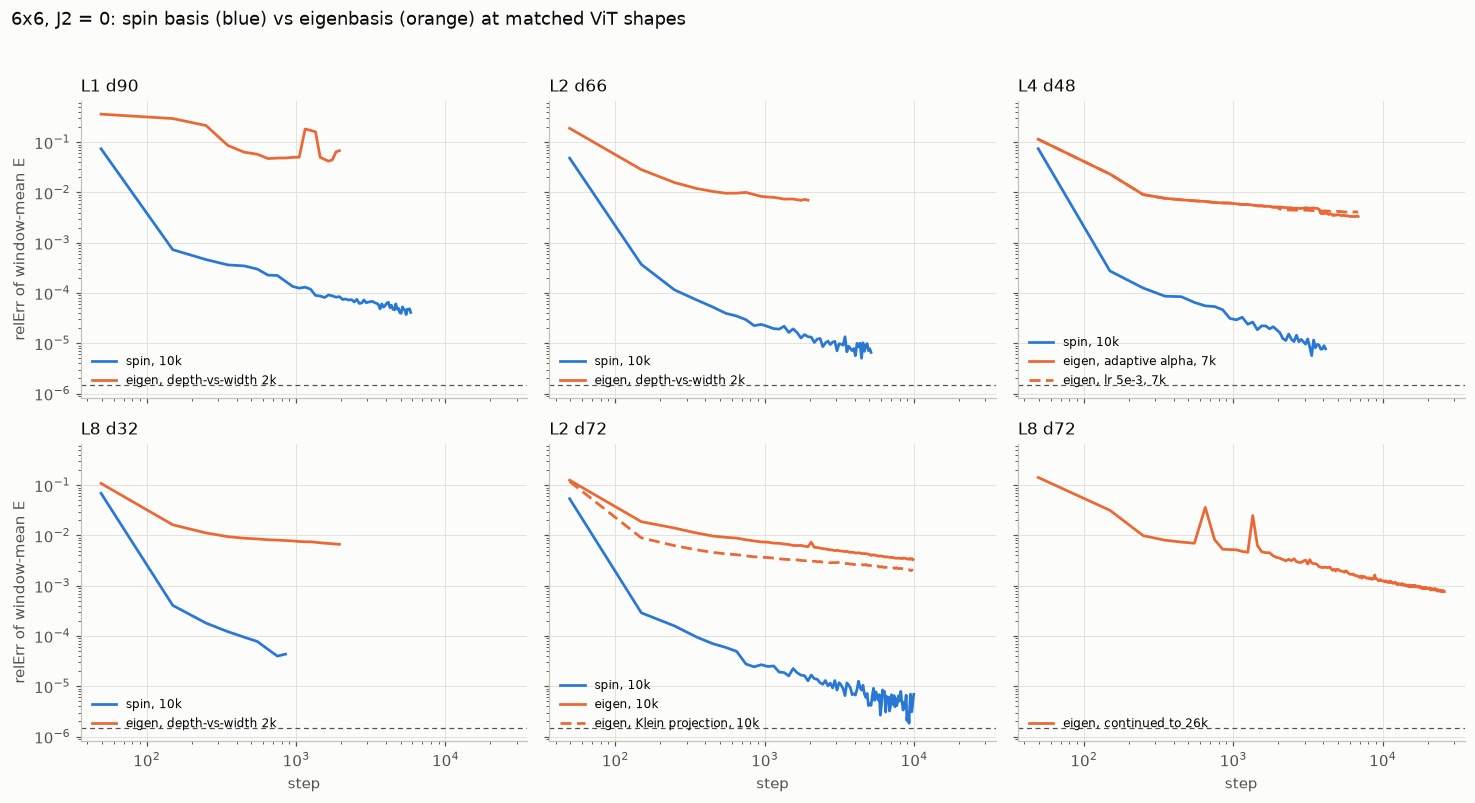

In [5]:
shapes = list(PAIRS)
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.4), sharex=True, sharey=True)
for ax, shape in zip(axes.flat, shapes):
    ax.set_title(shape, loc="left")
    count = {"spin": 0, "eigen": 0}
    for r in [r for r in RUNS if r["shape"] == shape]:
        s, E = r["steps"], r["E"]
        nwin = len(s) // SMOOTH
        if nwin == 0: continue
        sw = s[: nwin * SMOOTH].reshape(nwin, SMOOTH); Ew = E[: nwin * SMOOTH].reshape(nwin, SMOOTH)
        ok = np.isfinite(Ew).all(axis=1)
        ax.plot(sw.mean(axis=1)[ok], np.abs((Ew.mean(axis=1)[ok] - E0) / E0), color=C[r["basis"]],
                ls=LS[count[r["basis"]]], lw=1.8, label=r["label"])
        count[r["basis"]] += 1
    ax.axhline(1.5e-6, color=INK2, lw=0.8, ls=(0, (4, 3)))
    if not ax.lines[:-1]:
        ax.text(0.5, 0.5, "no data yet", transform=ax.transAxes, ha="center", color=INK2)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.legend(fontsize=8, loc="lower left")
for ax in axes[-1]: ax.set_xlabel("step")
for ax in axes[:, 0]: ax.set_ylabel("relErr of window-mean E")
fig.suptitle("6x6, J2 = 0: spin basis (blue) vs eigenbasis (orange) at matched ViT shapes",
             x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## 2. The gap at equal steps

relErr of the primary spin and eigenbasis run of every shape, at the latest
step both have reached (labelled). A line joins each pair; its length on the log
axis is the gap.

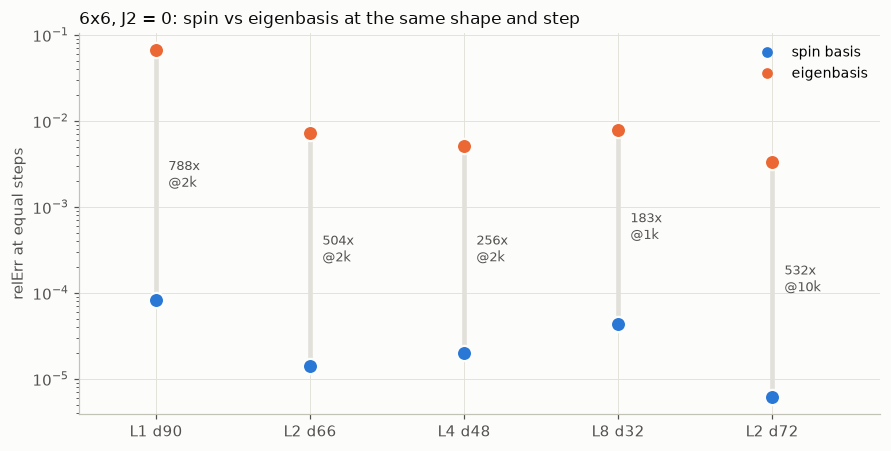

In [6]:
if GAPS:
    fig, ax = plt.subplots(figsize=(8.2, 4.2))
    for i, (shape, k, a, b) in enumerate(GAPS):
        ax.plot([i, i], [a, b], color=GRID, lw=3, zorder=1)
        ax.plot(i, a, "o", ms=10, color=C["spin"], mec=SURF, mew=1.5, zorder=3)
        ax.plot(i, b, "o", ms=10, color=C["eigen"], mec=SURF, mew=1.5, zorder=3)
        ax.annotate(f"{b / a:,.0f}x\n@{k // 1000}k", (i, np.sqrt(a * b)), xytext=(8, 0),
                    textcoords="offset points", va="center", color=INK2, fontsize=8.5)
    ax.set_xticks(range(len(GAPS)), [g[0] for g in GAPS])
    ax.set_yscale("log"); ax.set_ylabel("relErr at equal steps")
    ax.set_xlim(-0.5, len(GAPS) - 0.3)
    ax.plot([], [], "o", color=C["spin"], label="spin basis"); ax.plot([], [], "o", color=C["eigen"], label="eigenbasis")
    ax.legend(loc="upper right", fontsize=9)
    ax.set_title("6x6, J2 = 0: spin vs eigenbasis at the same shape and step", loc="left")
    fig.tight_layout()
    plt.show()

## 3. Reading (data fetched 2026-10-09; four of the five new spin runs in progress, L8 d72 not started)

- **The spin basis wins at every shape, by 2-3 orders of magnitude at equal
  steps:** roughly 180x (L8 d32, at 1k) to 800x (L1 d90, at 2k). The gap does not
  close with depth or width.
- **Depth matters much more for the eigenbasis.** A single layer (L1 d90) costs
  the eigenbasis a factor of ~10 against its 2-layer shapes (6.6e-2 vs 5-7e-3 at
  2k); the spin basis loses only ~5x (8.4e-5 vs ~1.5e-5).
- **Caveats.** Each basis runs at its own best-known alpha (spin 2.0, eigen
  1.25), most eigenbasis runs end at a 10x larger diag shift, and the deepest
  shapes are the least converged on the spin side so far. None of these is
  plausibly worth two orders of magnitude, but the L8 d72 pair (the eigenbasis's
  best run, 7.6e-4 at 26k) is the comparison to wait for.